# Onboarding: physics-constrained solar flare & SEP forecasting

This notebook is the orientation for the `SolarFlareForcast` project. Read it top to bottom once; every code cell is
light (seconds) and nothing here trains a model.

| Part | What you get |
|---|---|
| 1. Why this matters | Space weather, who uses these forecasts, NOAA R and S scales |
| 2. The data | GOES XRS soft X-rays and ≥10 MeV protons: what they measure, units, physics, real vs synthetic |
| 3. The ML problem | Sliding windows, persistence baseline, leakage-free splits |
| 4. The physics loss | Each penalty, where it comes from, and a toy demo of what it punishes |
| 5. Results so far | Tables and figures from `sweeps/` |
| 6. Kinks to work out | Honest limitations, ranked |
| 7. Future work | Projects that need your decisions, and topics I can walk you through |
| 8. Glossary | |

Run the setup cell first. It activates this project's environment, the same pattern as your other projects.

In [1]:
include("sol_setup.jl")
using CSV
show_png(path) = isdefined(Main, :IJulia) ? display("image/png", read(path)) : println("[figure] ", path)

SolarFlareForecast ready · Julia 1.12.6 · 1 threads


show_png (generic function with 1 method)

## 1. Why this matters

**Space weather** is the set of conditions on the Sun and in the solar wind that affect technology and people.
Two of the most direct hazards begin at the Sun within minutes to hours:

* **Solar flares.** Magnetic energy released in an active region heats coronal plasma to 10–30 MK. The X-ray burst
  reaches Earth in about 8 minutes and ionises the dayside D-layer of the ionosphere. That causes **HF radio blackouts**
  (aviation and maritime comms, over-the-horizon radar) and GNSS degradation.
* **Solar energetic particle (SEP) events.** Protons and ions accelerated to MeV–GeV energies by flares and by
  CME-driven shocks. They arrive in tens of minutes to hours. They cause **radiation dose** to astronauts (especially
  beyond low Earth orbit, e.g. Artemis), single-event upsets and solar-panel degradation on satellites,
  polar-cap absorption, and radiation exposure on polar flight routes.

NOAA's Space Weather Prediction Center (SWPC) issues alerts on two scales that map directly onto the two channels
this project forecasts:

| Radio blackout | GOES XRS-B peak | Radiation storm | ≥10 MeV protons |
|---|---|---|---|
| R1 minor | M1 (10⁻⁵ W m⁻²) | S1 minor | 10 pfu |
| R2 moderate | M5 | S2 moderate | 10² pfu |
| R3 strong | X1 (10⁻⁴) | S3 strong | 10³ pfu |
| R4 severe | X10 | S4 severe | 10⁴ pfu |
| R5 extreme | X20 | S5 extreme | 10⁵ pfu |

**Who cares (and who hires):** SWPC forecasters; NASA's Space Radiation Analysis Group (astronaut dose); satellite
operators; national-lab space-science groups that build and analyse particle instruments (e.g. LANL's energetic-particle
sensors flown on GPS satellites) and that need people comfortable with both instrument data and ML. The skill this
project shows, *ML that respects instrument physics and is evaluated honestly against an operational baseline*,
is the skill those groups look for.

## 2. The data

### 2a. GOES XRS: soft X-ray flux

The GOES-R series (GOES-16 to -19) carries the **X-Ray Sensor (XRS)**, with two broadband channels:

* **XRS-A** 0.05–0.4 nm (harder, more temperature-sensitive)
* **XRS-B** 0.1–0.8 nm. *This channel defines the flare class* (A, B, C, M, X = 10⁻⁸ … 10⁻⁴ W m⁻²; the number after the
  letter is a multiplier, so M2.3 = 2.3 × 10⁻⁵ W m⁻²).

Units are **W m⁻²** integrated over the band, at Earth. SWPC serves 1-minute averages. The emission is mostly
**thermal bremsstrahlung and lines from hot flare-loop plasma**, so the light curve is a thermodynamic record:

* **Impulsive phase** (minutes): electron beams deposit energy and chromospheric plasma "evaporates" into the loops.
  Flux rises fast. The **Neupert effect** says the soft X-ray flux tracks the *time integral* of the non-thermal
  energy input, so the soft X-ray *derivative* looks like the hard X-ray burst. That is why the model gets the
  1-minute XRS increment as an extra input channel.
* **Gradual phase** (tens of minutes to hours): the loops cool, first by thermal conduction and then by radiation.
  The flux decays roughly exponentially. It **cannot** drop faster than the fastest cooling time allows, which is
  the physics behind the decay-bound penalty in part 4.

The background between flares (the B–C level "quiet Sun") is set by how many active regions are on the disk. It
varies over hours to days, with a 27-day modulation from solar rotation.

Flare sizes follow a **power law**, dN/dF ∝ F^−α with α ≈ 1.8–2: many small flares, very few big ones. That makes
this a rare-event problem.

The cell below generates the project's synthetic 90-day telemetry and zooms in on its largest flare.

129600 one-minute samples; 687 flares: B=454, C=203, M=27, X=3; 5 SEP events


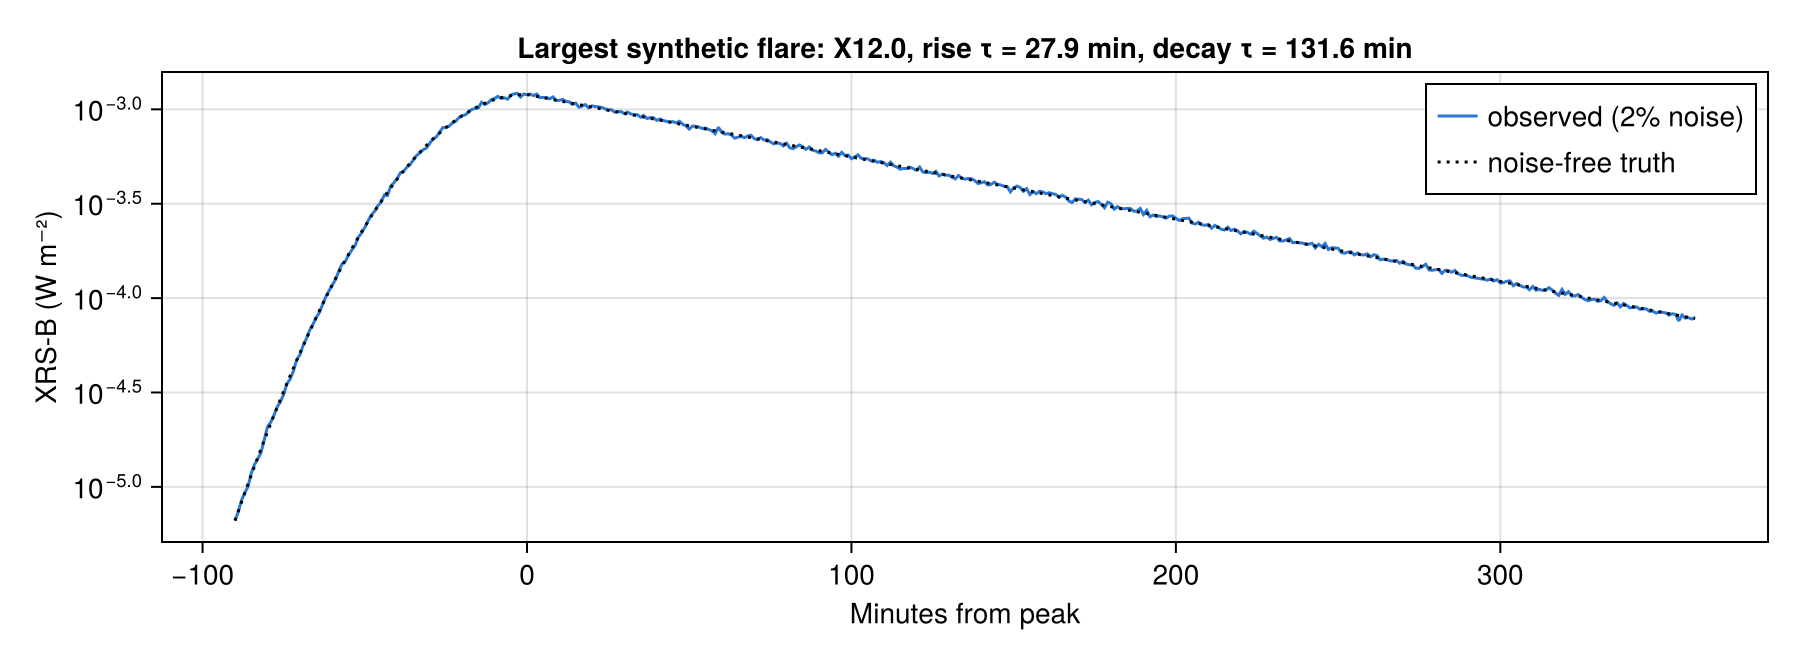

In [2]:
df, events = generate_telemetry(TelemetryConfig(seed = 42))
cls = first.(flare_class.(events.peak_flux))
println(nrow(df), " one-minute samples; ", nrow(events), " flares: ",
        join(["$(c)=$(count(==(c), cls))" for c in "BCMX"], ", "), "; ", count(events.sep), " SEP events")

k = argmax(events.peak_flux); ipk = events.peak_index[k]
r = max(1, ipk - 90):min(nrow(df), ipk + 360)
fig = Figure(size = (900, 330))
ax = Axis(fig[1, 1]; yscale = log10, xlabel = "Minutes from peak", ylabel = "XRS-B (W m⁻²)",
          title = "Largest synthetic flare: $(flare_class(events.peak_flux[k])), rise τ = $(round(events.rise_min[k]; digits=1)) min, decay τ = $(round(events.decay_min[k]; digits=1)) min")
lines!(ax, r .- ipk, df.xray[r]; color = "#2a78d6", label = "observed (2% noise)")
lines!(ax, r .- ipk, df.xray_clean[r]; color = :black, linestyle = :dot, label = "noise-free truth")
axislegend(ax; position = :rt)
fig

**Check the power law yourself.** On a log–log plot of the cumulative number of flares above a threshold, the slope is
−(α − 1) ≈ −0.9. A slope that changes with your threshold choice would be evidence of incompleteness (small flares
hidden under the background), a real issue with GOES catalogs.

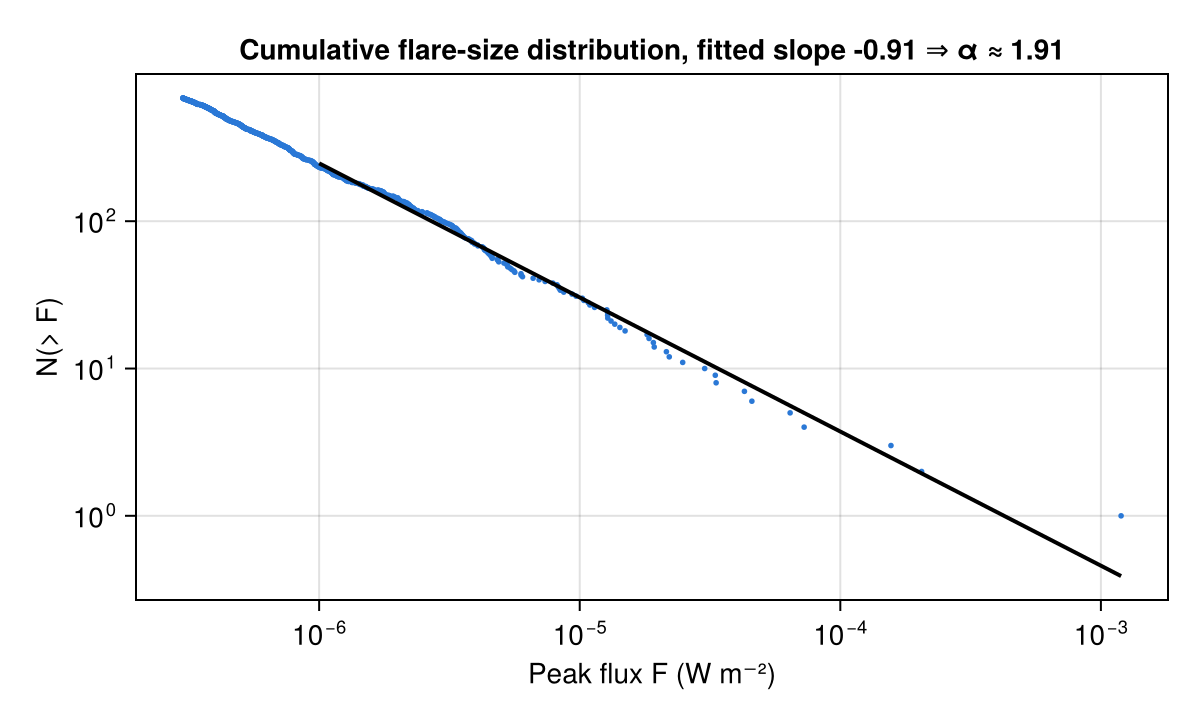

In [3]:
F = sort(events.peak_flux; rev = true)
N = 1:length(F)
sel = F .>= 1e-6                                     # fit above C1, where the catalog is complete
A = hcat(ones(count(sel)), log10.(F[sel]))
b = A \ log10.(N[sel])
fig = Figure(size = (600, 360))
ax = Axis(fig[1, 1]; xscale = log10, yscale = log10, xlabel = "Peak flux F (W m⁻²)", ylabel = "N(> F)",
          title = "Cumulative flare-size distribution, fitted slope $(round(b[2]; digits = 2)) ⇒ α ≈ $(round(1 - b[2]; digits = 2))")
scatter!(ax, F, N; markersize = 4, color = "#2a78d6")
lines!(ax, F[sel], 10 .^ (A * b); color = :black, linewidth = 2)
fig

### 2b. ≥10 MeV integral proton flux: the SEP channel

GOES-R measures protons with **SGPS** (Solar and Galactic Proton Sensor, part of the SEISS suite). SWPC publishes
*integral* fluxes, the number of protons above an energy threshold, in **pfu = particles cm⁻² s⁻¹ sr⁻¹**.
The ≥10 MeV channel defines the S scale. The quiet level is about 0.1–1 pfu (galactic cosmic rays plus instrument
background).

SEP physics in one paragraph: particles are accelerated in the flare reconnection region (*impulsive* events: short,
electron- and ³He-rich) and, for the biggest events, at the shock driven by a fast CME (*gradual* events: long and
proton-rich). They must then travel along the Parker-spiral magnetic field to Earth, so events from the Sun's
**western hemisphere** (magnetically connected) arrive faster and stronger. The fastest particles arrive first
(**velocity dispersion**), so onsets lag the flare by tens of minutes and the flux then rises for hours and decays
over a day or more as particles escape. That slow decay is why the proton decay bound in part 4 uses a
much longer timescale than the X-ray one.

The synthetic generator has the main ingredients (only ≥M1 flares can launch SEPs, probability and intensity grow with
flare size, transport delay, hours-long rise, day-long decay), but **not** connectivity or CMEs. More on that in
part 6.

SEP events (flare class → peak pfu):
  X2.1   → 277.9 pfu; flare peak → SEP peak 4.1 h
  M1.3   → 21.8 pfu; flare peak → SEP peak 4.1 h
  M1.8   → 24.7 pfu; flare peak → SEP peak 5.4 h
  X12.0  → 1982.6 pfu; flare peak → SEP peak 2.9 h
  M3.0   → 50.9 pfu; flare peak → SEP peak 5.6 h


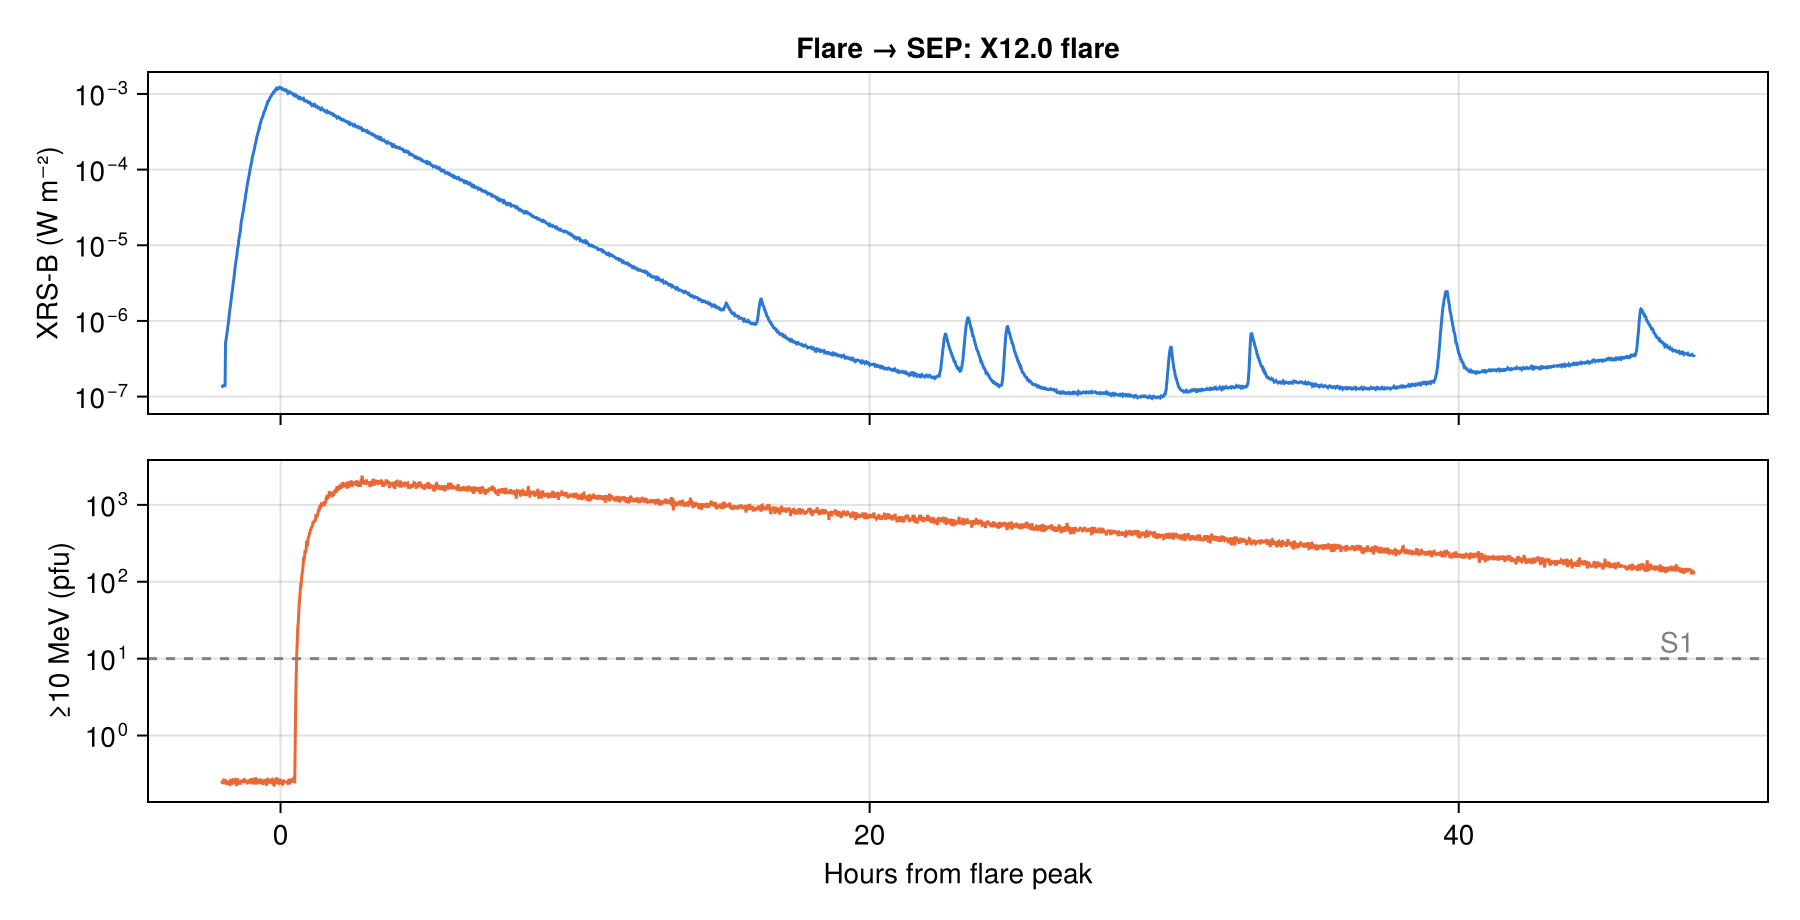

In [4]:
sep = events[events.sep, :]
println("SEP events (flare class → peak pfu):")
for e in eachrow(sep)
    println("  ", rpad(flare_class(e.peak_flux), 6), " → ", round(e.sep_peak_pfu; digits = 1), " pfu; flare peak → SEP peak ",
            round((e.sep_peak_index - e.peak_index) / 60; digits = 1), " h")
end
e = sep[argmax(sep.sep_peak_pfu), :]
r = max(1, e.peak_index - 120):min(nrow(df), e.peak_index + 48 * 60)
t = (r .- e.peak_index) ./ 60
fig = Figure(size = (900, 460))
ax1 = Axis(fig[1, 1]; yscale = log10, ylabel = "XRS-B (W m⁻²)", title = "Flare → SEP: $(flare_class(e.peak_flux)) flare", xticklabelsvisible = false)
ax2 = Axis(fig[2, 1]; yscale = log10, ylabel = "≥10 MeV (pfu)", xlabel = "Hours from flare peak")
linkxaxes!(ax1, ax2)
lines!(ax1, t, df.xray[r]; color = "#2a78d6")
lines!(ax2, t, df.proton[r]; color = "#eb6834")
hlines!(ax2, SEP_THRESHOLD_PFU; color = :gray, linestyle = :dash)
text!(ax2, t[end], SEP_THRESHOLD_PFU; text = "S1", align = (:right, :bottom), color = :gray)
fig

### 2c. Real data from NOAA SWPC

`load_swpc()` pulls SWPC's live 7-day JSON products (`xrays-7-day.json`, `integral-protons-7-day.json`) and puts them on
the **same schema** as the synthetic data (`time, minute, xray, proton`). Everything downstream works unchanged.
Every download is cached in `data/raw/` with a UTC timestamp, and `load_swpc_cache()` merges all cached downloads.
Running `load_swpc()` once a week therefore grows a continuous real dataset. For multi-year training sets the
source is the NCEI GOES-R archive (netCDF; would add `NCDatasets.jl`).

Things real data has that the synthetic data doesn't. Spot them in the plot:
* **Data gaps** and dropped rows (the windowing code refuses to build a window across a gap).
* **Eclipse season** near the equinoxes. The satellite passes through Earth's shadow around local midnight, which
  causes dips or dropouts in the X-ray record.
* **Primary/secondary satellite switches**, small calibration offsets, and particle contamination of the XRS.

9997 real one-minute rows, 2026-10-12T02:45:00 → 2026-10-19T02:30:00; largest flare M1.4


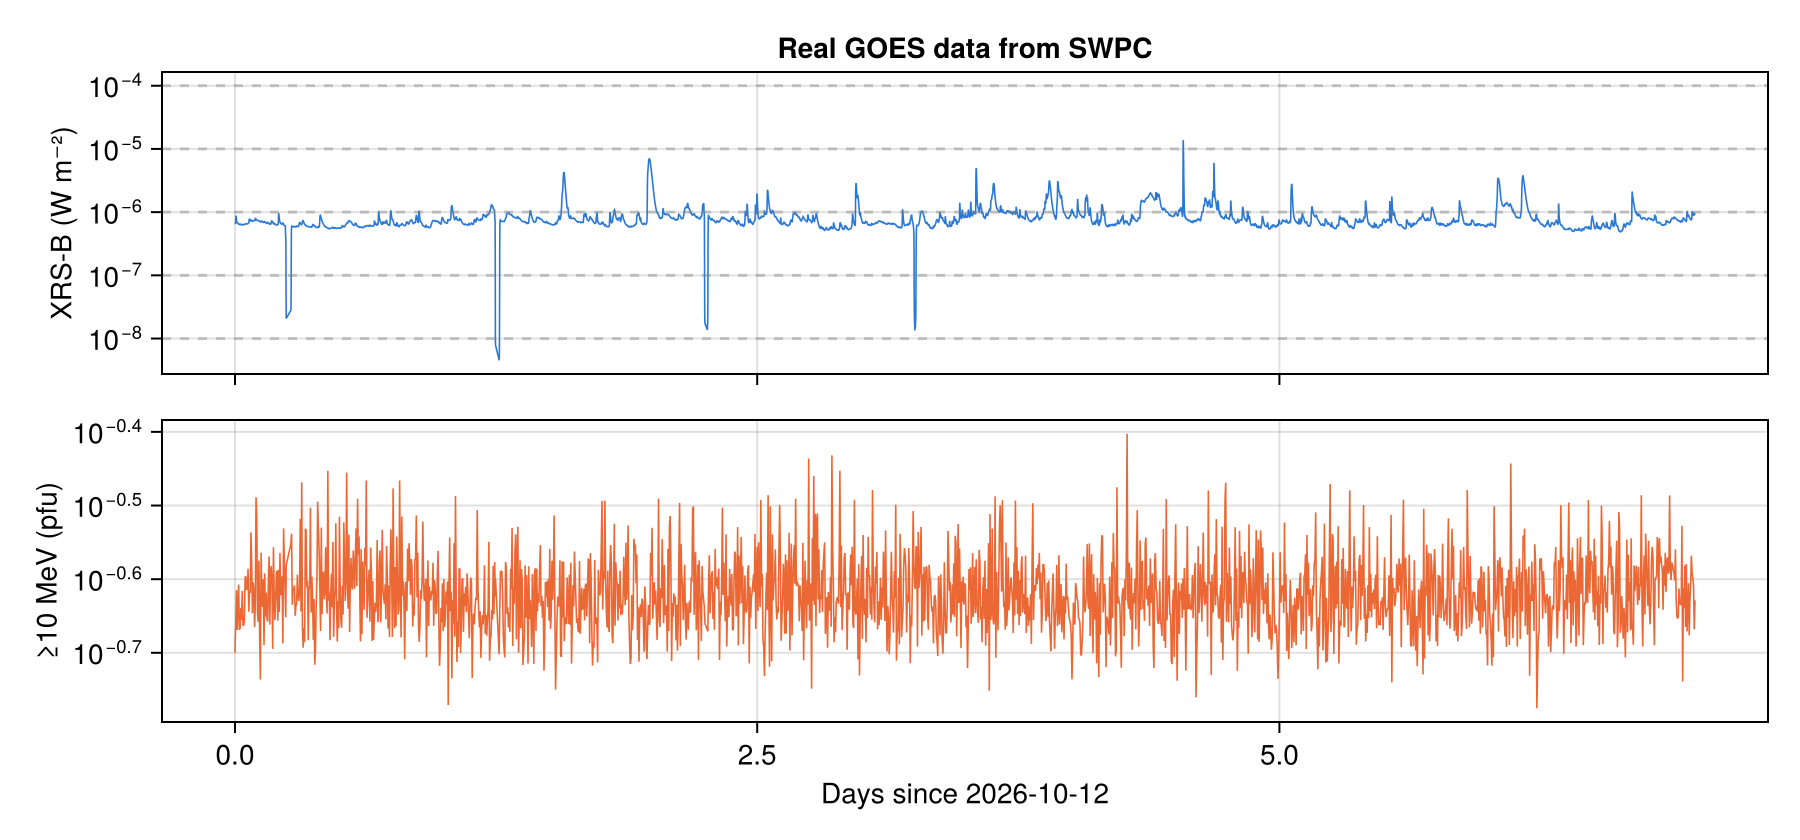

In [5]:
real = try
    load_swpc_cache()
catch err
    println("No cached SWPC data yet. Run `load_swpc()` once (needs internet).  ", err)
    nothing
end
if real !== nothing
    println(nrow(real), " real one-minute rows, ", first(real.time), " → ", last(real.time),
            "; largest flare ", flare_class(maximum(real.xray)))
    d = real.minute ./ 1440
    fig = Figure(size = (900, 420))
    ax1 = Axis(fig[1, 1]; yscale = log10, ylabel = "XRS-B (W m⁻²)", title = "Real GOES data from SWPC", xticklabelsvisible = false)
    ax2 = Axis(fig[2, 1]; yscale = log10, ylabel = "≥10 MeV (pfu)", xlabel = "Days since $(Date(first(real.time)))")
    linkxaxes!(ax1, ax2)
    lines!(ax1, d, real.xray; color = "#2a78d6", linewidth = 0.8)
    lines!(ax2, d, real.proton; color = "#eb6834", linewidth = 0.8)
    for (l, v) in pairs(XRAY_CLASS_FLOOR); hlines!(ax1, v; color = (:gray, 0.4), linestyle = :dash); end
    fig
end

## 3. The ML problem

**Task:** given the last **W = 180 min** of both channels, predict the next **H = 60 min** of both, minute by
minute, in log₁₀ flux. Log space is natural because flux spans 5+ decades and errors are multiplicative.
A 0.1 dex error is a 26% flux error at any flare size.

Design choices you should be able to defend in an interview:

1. **Persistence baseline.** "The next hour looks like now" is hard to beat at short lead times and is the standard
   operational reference. Any skill claim is *relative to persistence*.
2. **Residual architecture.** The CNN predicts the *change* from the last observation, ŷ = x_last + f(x). Its last
   layer starts at zero, so an untrained model *is* persistence, and training only adds what the data supports.
3. **Chronological split with guard gaps.** Train on days 0–63, validate on the next 13.5, test on the last 13.5. A gap of
   W + H rows between splits means no test window shares a single minute with a training window. Random splits of
   overlapping windows leak the answer and inflate scores, a very common mistake in published ML papers.
4. **Standardise with training statistics only**, for the same reason.
5. **Test set is sealed.** Weights and λ are chosen on validation. The test split is scored once.

In [6]:
data = prepare_data(df; W = 180, H = 60)
println("train X ", size(data.train.X), "   (window minutes, channels, windows)")
println("val   X ", size(data.val.X), "   test X ", size(data.test.X))
println("standardiser μ = ", round.(data.scaler.μ; digits = 2), " (log10 units), σ = ", round.(data.scaler.σ; digits = 2))
println("rows: ", data.rows)

train X (180, 3, 30161)   (window minutes, channels, windows)
val   X (180, 3, 18961)   test X (180, 3, 18961)
standardiser μ = Float32[-6.48, -0.19] (log10 units), σ = Float32[0.48, 0.84]
rows: (train = 1:90720, val = 90961:110160, test = 110401:129600)


## 4. The physics-informed loss

Total loss = MSE + λ_decay·P_decay + λ_rough·P_rough + λ_convex·P_convex. Each penalty is computed on the forecast in
physical units (dex = log₁₀ flux), with the last observed point prepended so the jump from *now* into the forecast is
also constrained.

**P_decay, the cooling bound (one-sided).** If plasma cools with e-folding time τ, then F ∝ e^{−t/τ} and
d log₁₀F/dt = −1/(τ ln 10). With a minimum physical cooling time τ_min (5 min for X-rays, 3 h for SEP protons),
any faster drop is unphysical:

$$P_\text{decay} = \big\langle \text{ReLU}\big(-\Delta_t \log_{10}\hat F - \tfrac{1}{\tau_\min \ln 10}\big)^2 \big\rangle$$

Rises are **not** penalised. The impulsive phase really can be arbitrarily fast. This *asymmetry* is the key
difference from generic smoothing.

**P_rough, quiet-Sun curvature.** The squared second difference of the X-ray forecast, multiplied by a soft gate that
is ≈1 only when the last 30 min of input varied by less than 0.15 dex. It removes high-frequency wiggles on a quiet
background but leaves flares alone. Protons are always smooth at 1-min cadence, so their curvature is penalised
everywhere.

**P_convex, gradual-phase shape.** An exponential decay on top of a constant background is a *convex* curve in log space:
the decline slows as the flux approaches background. During a decay (input below its 60-min peak and falling), concave
bends are penalised.

**Ablation: naive smoothing.** Your original prototype penalised every first difference equally. That also flattens
genuine flare rises. It is kept as a comparison model.

The toy demo below builds four hand-made 60-min forecasts from the same quiet input and prints what each penalty says.

In [7]:
σ = data.scaler.σ
quiet, _ = regime_gates(data.test.X, σ[1], 0.15f0)
n = findfirst(>(0.95f0), vec(quiet))                    # a quiet test window
x = data.test.X[:, :, n:n]
last_ = x[end, 1:2, 1]
H = 60
smooth = repeat(reshape(last_, 1, 2, 1), H, 1, 1)
jagged = smooth .+ 0.05f0 .* randn(Xoshiro(1), Float32, H, 2, 1)   # ±0.05σ wiggles
fastdrop = copy(smooth); fastdrop[:, 1, 1] .-= Float32.(0.4 .* (1:H) ./ σ[1])  # −0.4 dex/min: faster than any cooling
naive_risk = copy(smooth); naive_risk[20:end, 1, 1] .+= Float32(1.0 / σ[1])    # sudden 1-dex rise (a real flare could do this)
L = PhysicsLoss()
for (name, ŷ) in ("flat (persistence)" => smooth, "jagged" => jagged, "too-fast decay" => fastdrop, "sudden rise" => naive_risk)
    p = physics_terms(L, ŷ, x, σ)
    @printf("%-20s decay %.2e   rough %.2e   convex %.2e   naive %.2e\n", name, p.decay, p.rough, p.convex, p.naive)
end

flat (persistence)   decay 0.00e+00   rough 0.00e+00   convex 0.00e+00   naive 0.00e+00
jagged               decay 2.39e-03   rough 2.26e-02   convex 0.00e+00   naive 6.49e-03
too-fast decay       decay 9.81e-02   rough 2.15e-12   convex 0.00e+00   naive 3.52e-01
sudden rise          decay 0.00e+00   rough 3.29e-02   convex 0.00e+00   naive 3.73e-02


Read the table row by row:
* *jagged*: `rough` (and `naive`) fire. That is the quiet-time artifact we want to kill. `decay` fires a little too, from the
  **proton** channel: its bound is tight (3-h decay time ≈ 0.0024 dex/min), so random downward wiggles break it.
* *too-fast decay*: `decay` fires hard. That's the unphysical drop.
* *sudden rise*: `decay` stays zero (rises are allowed) and `naive` fires. A one-step jump also has curvature, so
  `rough` fires a little on a quiet window, which is why its gate matters.

## 5–8. Results, kinks, future work, glossary

*Being written overnight from the actual sweep results. This notebook will be regenerated in the morning of 2026-10-19; if you have it open in VS Code then, close and reopen it to see the new sections.*